# DSML Group Project — Executed Results

## Predicting Delivery Risk and Customer Dissatisfaction in E-Commerce Using Machine Learning

This notebook contains the **actual results obtained from the uploaded Olist datasets**. The full analysis was run section-by-section to avoid memory/time failures from running every heavy model in one monolithic kernel. Random Forest, Logistic Regression and Decision Tree use the full classification dataset; SVM/Naive Bayes use a reproducible 10,000-order sample; Bagging/Boosting/XGBoost use a reproducible 20,000-order sample.

## 1. Final integrated dataset

In [ ]:
# Final data summary (already executed)

Order-level rows: 99,441
Columns after integration/feature engineering: 47
Orders with observed delivery outcome: 96,476
Late-delivery rate: 8.11%
Average delivery time: 12.56 days
Median delivery time: 10.22 days
Average review score: 4.09/5
Overall dissatisfaction rate (review <= 2): 14.64%
Median seller-customer distance: 433.3 km


## 2. Feature Selection

In [ ]:
# Filter, Wrapper (RFE), and Embedded (Lasso) feature-selection results

RFE selected features:
- distance_km
- freight_value
- order_value
- payment_value
- promised_days
- same_state
- seller_count
- total_weight_g

Top Mutual Information features for delivery-time regression:
promised_days    0.503024
purchase_hour    0.345582
distance_km      0.215052
purchase_dow     0.190701
freight_value    0.142538

Top Lasso features (absolute standardized coefficients):
distance_km       2.347037
promised_days     1.739793
same_state       -1.324569
purchase_dow      0.358343
total_weight_g    0.347472


## 3. PCA

In [ ]:
# PCA result

Principal components needed for >=80% explained variance: 9
Principal components needed for >=90% explained variance: 12


## 4. Regression — Predicting Delivery Time

Simple regression: delivery_days ~ distance_km
{
  "coef": 0.005994862358239972,
  "intercept": 8.641762183869538,
  "MAE": 5.2756897376809135,
  "RMSE": 7.304492113786788,
  "R2": 0.190143390052675
}

Regularized / multiple regression comparison:
      Model      MAE     RMSE       R2
      Ridge 4.836379 6.881008 0.303595
        OLS 4.837216 6.882034 0.303387
      Lasso 4.854967 6.896208 0.300515
Elastic Net 4.855331 6.896306 0.300495

Non-linear models:
              Model     RMSE       R2
Polynomial degree 2 7.348886 0.215084
         Linear-log 7.419465 0.199935
            Log-log 7.519469 0.178222
         Log-linear 7.780185 0.120249

OLS diagnostics:
{
  "R2": 0.25606613418055557,
  "Adj_R2": 0.25585776602031485,
  "Durbin_Watson": 2.0004407478292165,
  "Breusch_Pagan_LM_p": 2.0095764200798495e-145,
  "Breusch_Pagan_F_p": 1.6800841698767824e-147
}


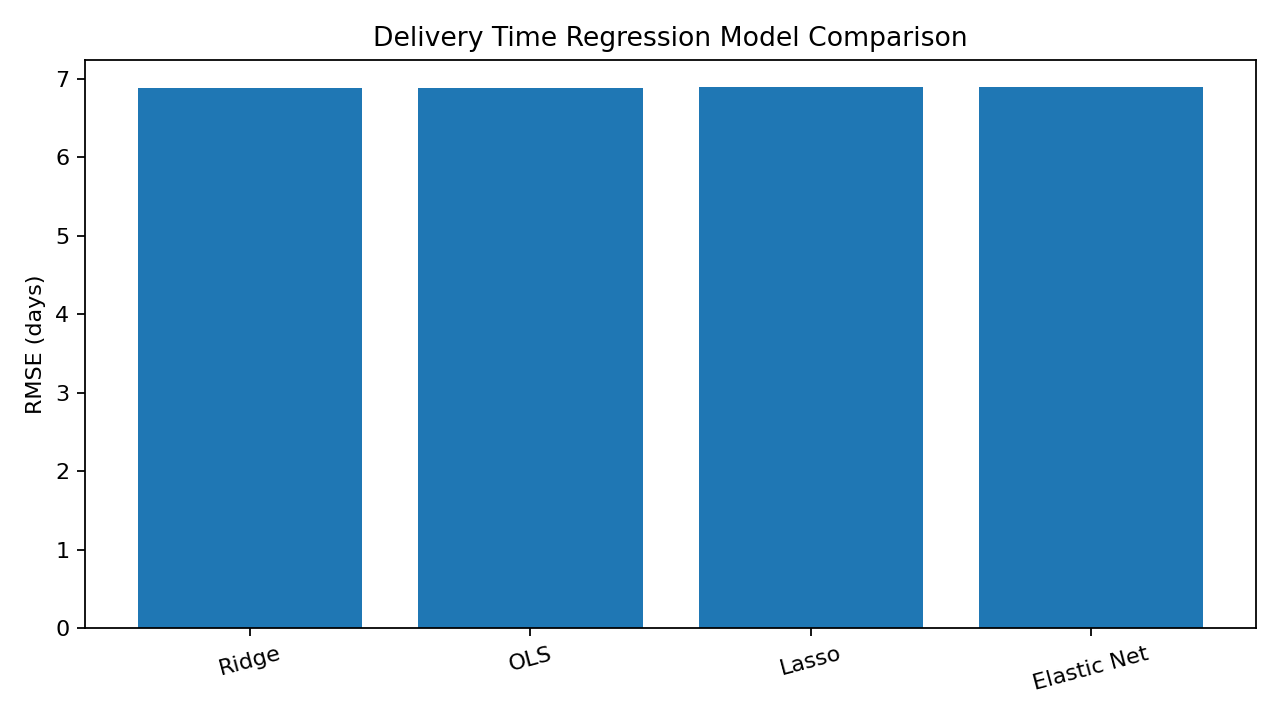

In [ ]:
# Regression outputs

### Regression interpretation
- **Ridge Regression performed best**: RMSE = **6.88 days**, MAE = **4.84 days**, R² = **0.304**.
- Distance alone explains about **19.0%** of delivery-time variation.
- The Breusch–Pagan test is highly significant, indicating heteroskedastic residuals in the OLS specification. Durbin–Watson is approximately 2, indicating little residual autocorrelation in the sampled cross-sectional regression.

## 5. Classification — Predicting Late Delivery

Full-data base classifiers:
              Model  Accuracy  Precision   Recall       F1  ROC_AUC
      Random Forest  0.894797   0.328918 0.285623 0.305746 0.766052
      Decision Tree  0.738754   0.180867 0.629393 0.280987 0.742547
Logistic Regression  0.654436   0.138751 0.626198 0.227167 0.698390

SVM / Naive Bayes (10,000-order sample):
      Model  Accuracy  Precision   Recall       F1  ROC_AUC  Sample_N
  SVM (RBF)    0.6575   0.129213 0.585987 0.211738 0.670594     10000
Naive Bayes    0.1235   0.080000 0.968153 0.147788 0.574313     10000

Ensembles (20,000-order sample):
                       Model  Accuracy  Precision   Recall       F1  ROC_AUC  Sample_N
Stochastic Gradient Boosting   0.91925   0.000000 0.000000 0.000000 0.758331     20000
           Gradient Boosting   0.91925   0.333333 0.003106 0.006154 0.755947     20000
                     Bagging   0.91825   0.407407 0.034161 0.063037 0.712220     20000

XGBoost (20,000-order sample):
  Model  Accuracy  Precision   Rec

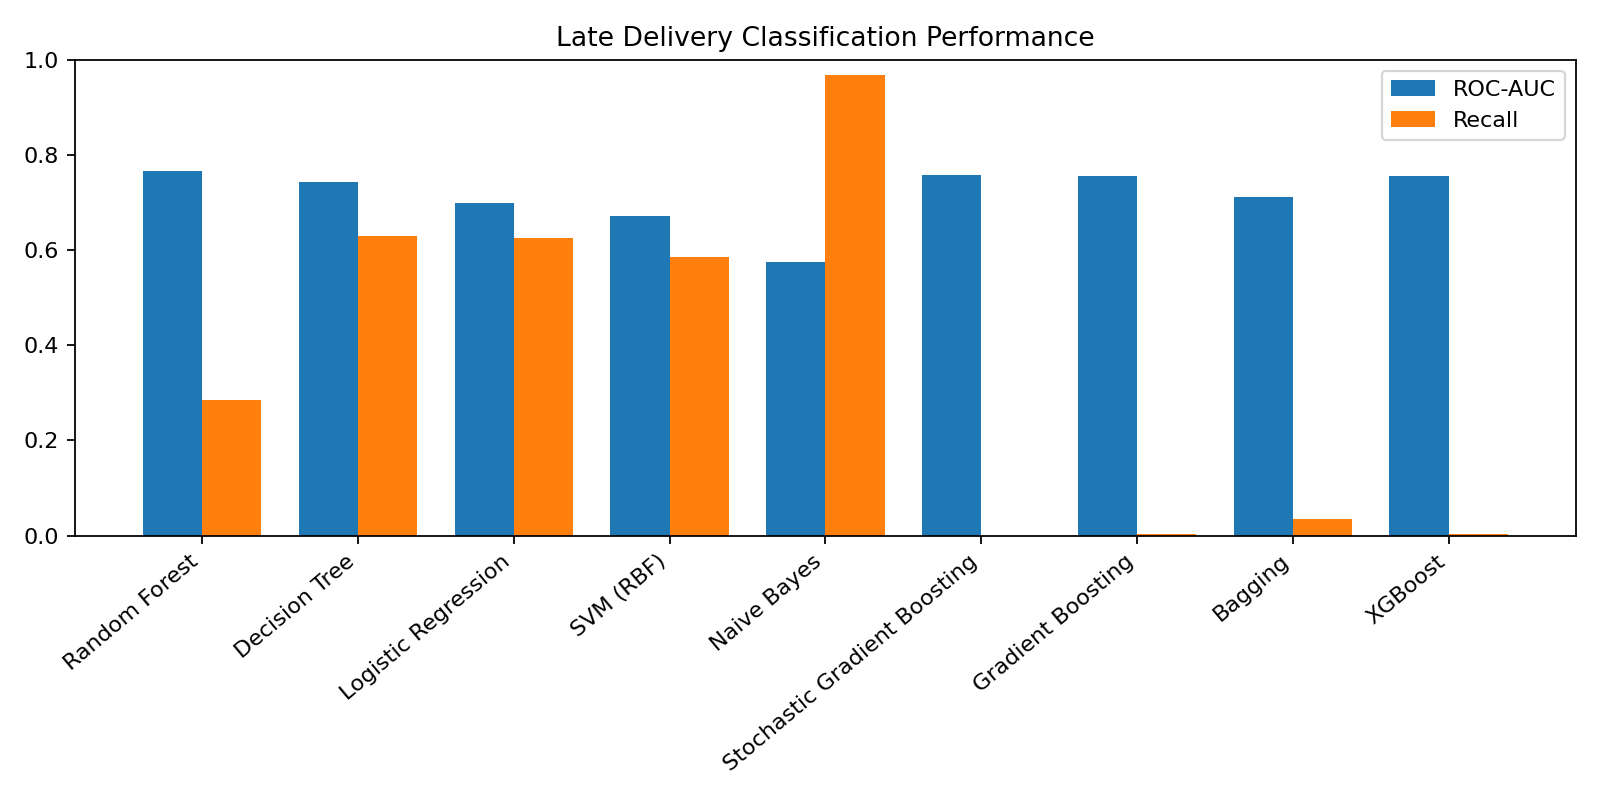

In [ ]:
# Classification results

### Classification interpretation
- **Random Forest has the highest ROC-AUC among the full-data base models (≈0.766)**, so it is the strongest overall ranking model in the main comparison.
- **Decision Tree has much higher recall (≈0.629)** than Random Forest at the default 0.50 threshold, though with lower precision and lower ROC-AUC.
- Gradient Boosting/XGBoost rank orders reasonably well by ROC-AUC, but the default 0.50 decision threshold predicts almost no late orders because only ~8.1% of orders are late. This is a class-imbalance/threshold issue, not evidence that the probability models contain no signal.
- For the PPT, compare **ROC-AUC + Recall + F1**, not Accuracy alone.

## 6. Random Forest — Most Important Predictors

promised_days              0.155392
purchase_month             0.123171
distance_km                0.100643
freight_value              0.075326
mean_product_volume_cm3    0.067746
freight_ratio              0.064434
payment_value              0.061568
avg_item_price             0.055022
avg_weight_g               0.053829
order_value                0.053748
total_weight_g             0.053332
purchase_hour              0.048815
purchase_dow               0.031646
payment_installments       0.026505
same_state                 0.013818


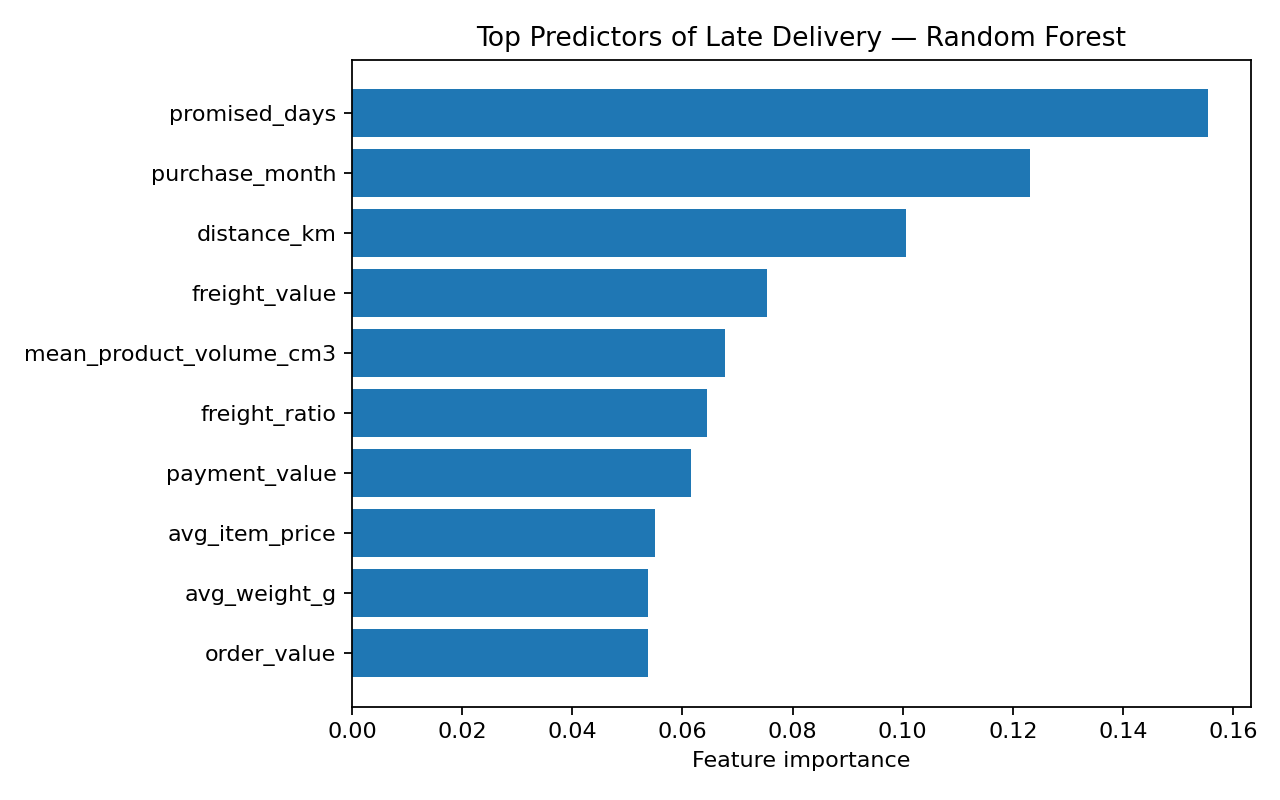

In [ ]:
# Random Forest feature importance

The strongest Random Forest predictors are **promised delivery window, purchase month, seller–customer distance, freight value, product volume and freight ratio**. These are predictive associations, not causal effects.

## 7. Seller Segmentation

K-Means evaluation:
 k      inertia  silhouette
 2 19909.482166    0.466455
 3 16254.601330    0.483936
 4 13726.283498    0.492638
 5 11699.619048    0.473798
 6 10479.286502    0.267154
 7  9562.296333    0.272860
 8  8805.148750    0.270801

Best k = 4 (silhouette = 0.493)

K-Means cluster counts: {'0': 2500, '1': 120, '2': 452, '3': 23}

Cluster profiles:
 kmeans_cluster     orders       revenue  avg_item_price  avg_freight  avg_delivery_days  late_rate  avg_review_score  dissatisfaction_rate
              0  29.537200   3622.367676      128.493863    20.409331          10.951996   0.055902          4.295802              0.094706
              1   9.108333   8815.330667     1244.348326    84.174480          14.117275   0.086956          4.134499              0.160111
              2   6.234513   1153.487566      158.056336    23.799998          20.139588   0.282629          2.135216              0.684789
              3 967.652174 128543.845652      162.098739    20.851979         

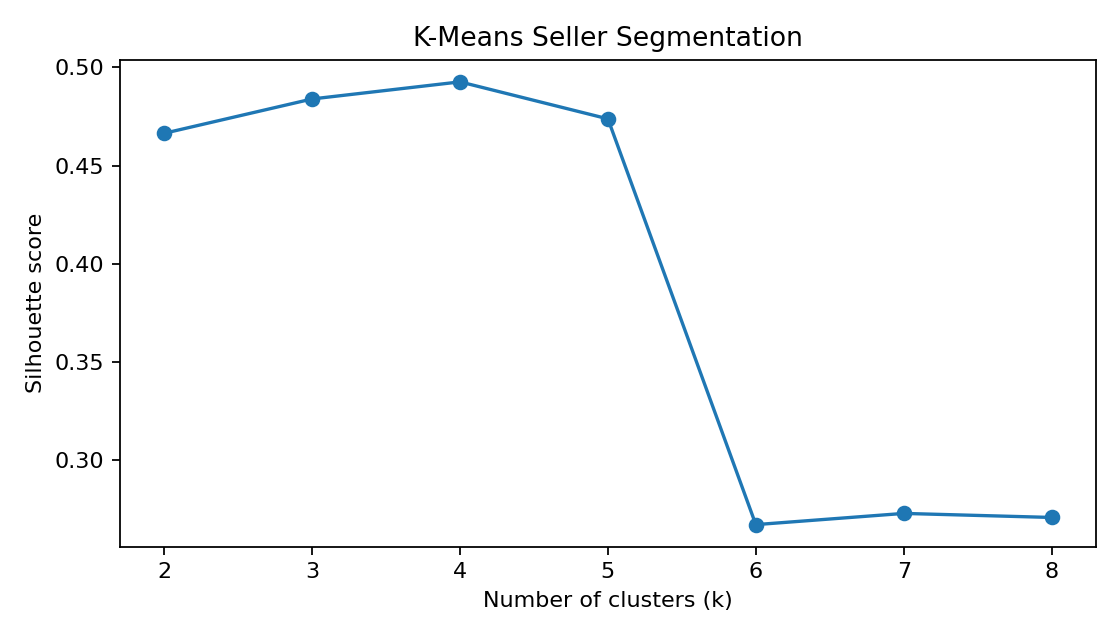

In [ ]:
# Seller clustering results

### Suggested business labels for K-Means clusters
- **Cluster 0 — Reliable mainstream sellers:** low late rate (~5.6%), high reviews (~4.30), moderate volume.
- **Cluster 1 — Premium/high-ticket sellers:** high average price and freight, moderate delivery performance.
- **Cluster 2 — Operationally risky sellers:** very high late rate (~28.3%), low reviews (~2.14), dissatisfaction ~68.5%.
- **Cluster 3 — High-volume strategic sellers:** extremely high order volume/revenue, moderate late rate (~7.9%) and review score (~4.03).

## 8. Delivery Performance vs Customer Dissatisfaction

 late_delivery  orders  avg_review_score  dissatisfaction_rate  avg_delivery_days
           0.0   88168          4.294151              0.091915          10.878160
           1.0    7662          2.566562              0.539807          31.378625


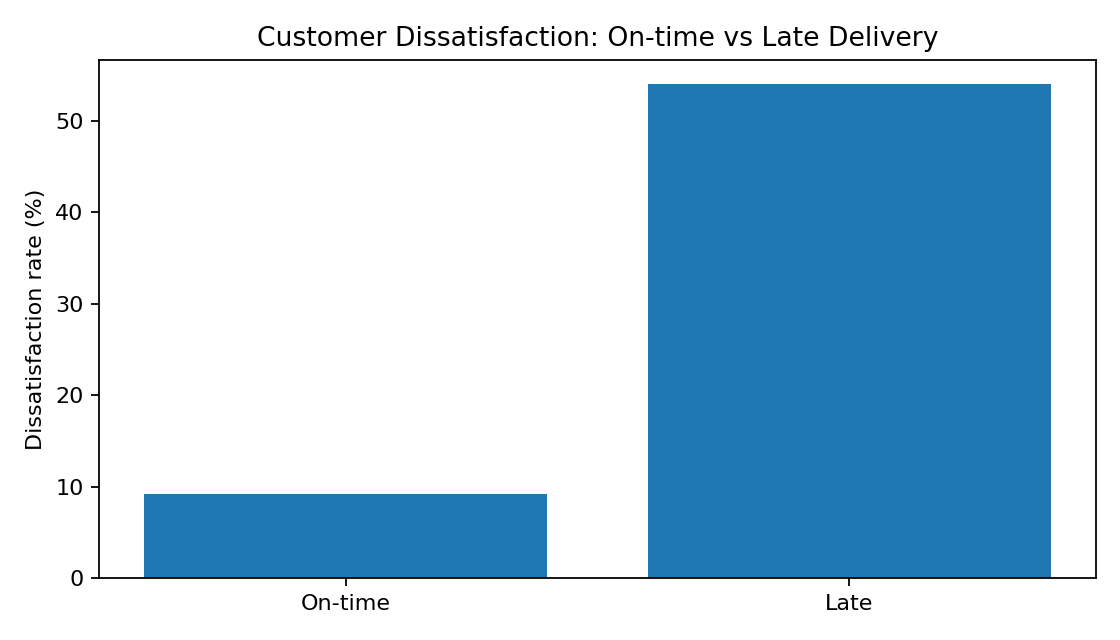

In [ ]:
# Customer experience comparison

### Key customer-experience result
- On-time orders: average review **4.29/5**, dissatisfaction **9.19%**, average delivery **10.88 days**.
- Late orders: average review **2.57/5**, dissatisfaction **53.98%**, average delivery **31.38 days**.

Late deliveries are therefore strongly **associated** with worse customer experience in this dataset.

## 9. Holt-Winters Revenue Forecast

{
  "n_days": 727,
  "start": "2016-09-04",
  "end": "2018-08-31",
  "train_end": "2018-08-01",
  "test_start": "2018-08-02",
  "test_end": "2018-08-31",
  "MAE": 13996.495456485754,
  "RMSE": 19354.809304545186,
  "actual_test_total": 814132.53,
  "forecast_test_total": 1138104.1517392055,
  "actual_test_mean": 27137.751,
  "forecast_test_mean": 37936.80505797351
}


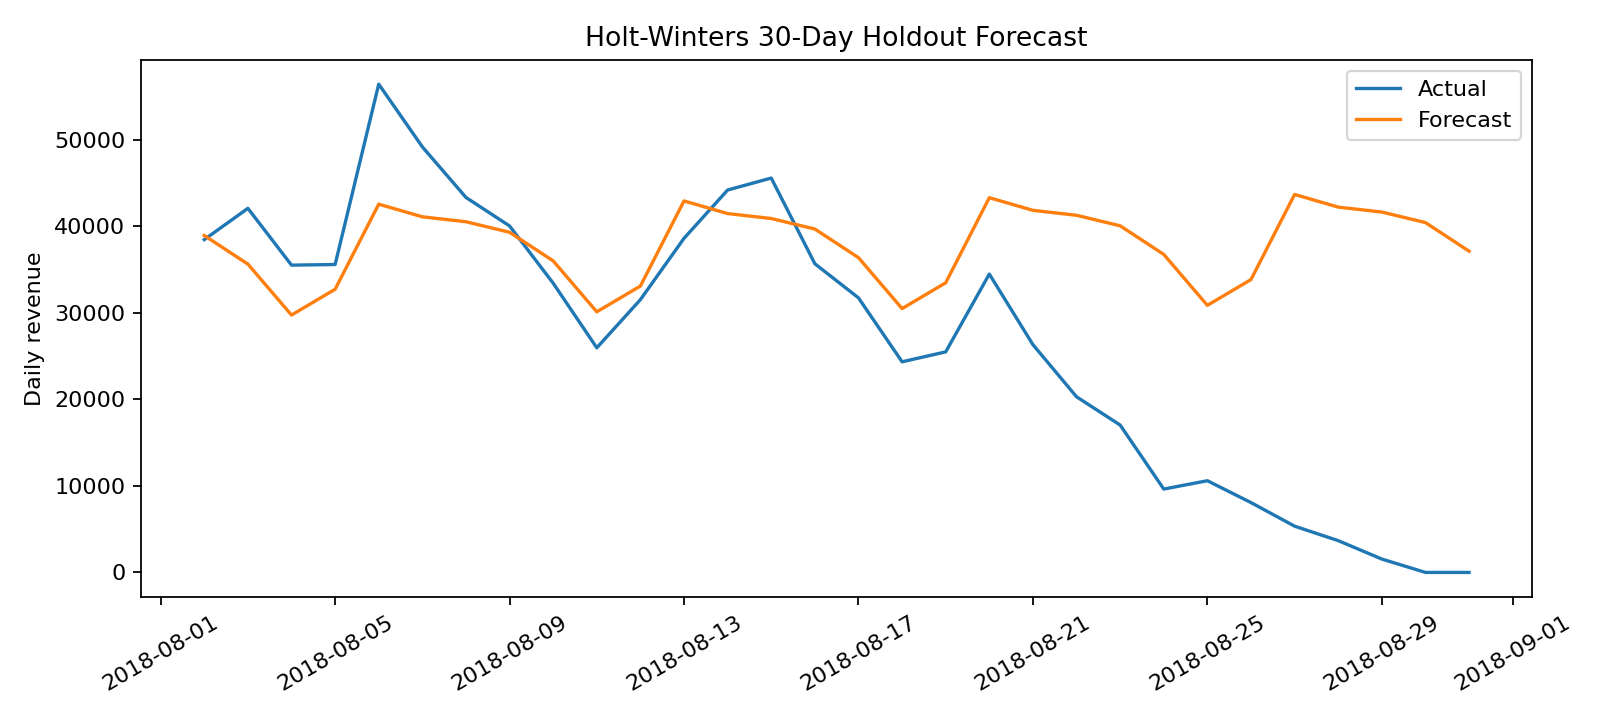

In [ ]:
# 30-day Holt-Winters holdout results

### Forecast interpretation
Using the last complete month (through 31 Aug 2018) and a 30-day holdout, Holt-Winters produced **MAE ≈ 13,996** and **RMSE ≈ 19,355** in daily revenue units. It over-forecast the holdout total (**1,138,104 forecast vs 814,133 actual**), so it should be presented as a baseline time-series model rather than a highly accurate final forecasting system.

## 10. Final Project Conclusions
1. Delivery time is partially predictable: Ridge achieved **RMSE ≈ 6.88 days** and **R² ≈ 0.304**.
2. Late delivery is highly imbalanced (~8.1%). Random Forest provided the best full-data ROC-AUC (~0.766), while Decision Tree provided higher recall at the default threshold.
3. Four seller clusters were supported by the best K-Means silhouette score; one cluster is clearly operationally risky with high delays and poor reviews.
4. Late delivery is associated with a dramatic increase in dissatisfaction (about **9.2% → 54.0%**).
5. Holt-Winters provides a usable baseline for short-term demand/revenue planning but over-forecast the final complete-month holdout.

### PPT recommendation
Use **Random Forest** as the main late-delivery ranking model, show **Decision Tree** as the recall-oriented alternative, highlight the **4 seller segments**, and make the late-vs-on-time dissatisfaction result the strongest managerial insight.